# P7. 베타–이항: 비율을 추정하는 베이지안 기본기

**목표**
- Beta 분포가 "0~1 사이 비율에 대한 믿음"을 그리는 도구라는 것을 모양으로 익힙니다.
- Beta 사전 + 이항 데이터 → Beta 사후(**켤레**, conjugacy)를 숫자 두 개 더하기로 이해합니다.
- 사전의 세기(a + b)가 "가상의 관측 수"처럼 작동하는 것을 봅니다.
- 신용구간과 신뢰구간이 무엇이 다른지 시뮬레이션으로 봅니다.
- 사후 예측과 두 군 비교를 사후 표본으로 합니다.
- 시퀀싱: 낮은 깊이 VAF, 정상 시료들의 오류가 이항보다 더 퍼지는 과분산(베타–이항), 정상 시료에 섞인 종양 비율.

**이 노트북이 답하는 질문**: read 몇 개로 VAF 를 추정할 때, 그 값을 얼마나 믿을 수 있고 다음 read 는 어떻게 나올까?

**같이 볼 강의·교재**
- Harvard Stat 110 (Blitzstein), 23강 "Beta distribution" [2]
- Downey, *Think Bayes* 2판, 4장 "Estimating Proportions", 18장 "Conjugate Priors" [3]
- BDA3, 2.1–2.4 절(이항 데이터, 사후 요약, 켤레 사전), 4.4 절(신뢰 범위) [1]

In [1]:
# 그림 도구 (펼치지 않아도 됩니다). 팔레트: Okabe-Ito, 뜻 고정 — 사전 하늘, 우도 주황, 사후 파랑, 증거 진회색, 핵심 자주
import logging, math, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from scipy import stats, special

warnings.filterwarnings("ignore", category=RuntimeWarning)
COL = dict(prior="#56B4E9", likelihood="#E69F00", posterior="#0072B2", evidence="#374151",
           highlight="#CC79A7", ink="#222222", muted="#6B7280", grid="#E5E7EB", none="#D1D5DB",
           ok="#009E73", alt="#D55E00", ref="#9CA3AF", shade="#F3F4F6")

def apply_theme():
    logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # 글꼴 대체 경고 숨김
    plt.rcParams.update({
        "font.family": ["Arial", "DejaVu Sans"], "font.size": 10.5, "mathtext.fontset": "dejavusans",
        "axes.titlesize": 11.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
        "axes.titlepad": 10, "axes.labelsize": 10.5, "axes.labelcolor": COL["ink"],
        "axes.edgecolor": "#9CA3AF", "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": False, "grid.color": COL["grid"], "grid.linewidth": 0.8,
        "xtick.color": COL["muted"], "ytick.color": COL["muted"],
        "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
        "legend.frameon": False, "legend.fontsize": 9.5,
        "figure.dpi": 110, "savefig.bbox": "tight", "figure.facecolor": "white"})

def panel(ax, letter, title):
    """왼쪽 정렬 'A   제목'"""
    ax.set_title(f"{letter}   {title}")

def note(ax, x, y, text, **kw):
    """회색 작은 주석"""
    kw.setdefault("fontsize", 9); kw.setdefault("color", COL["muted"])
    return ax.text(x, y, text, **kw)

def callout(ax, x, y, text, **kw):
    """핵심 메시지 한 줄: 자주색 굵은 글씨, 흰 바탕"""
    kw.setdefault("fontsize", 10); kw.setdefault("color", COL["highlight"]); kw.setdefault("fontweight", "semibold")
    kw.setdefault("bbox", dict(facecolor="white", edgecolor="none", pad=1.5, alpha=0.9))
    return ax.text(x, y, text, **kw)

def ygrid(ax):
    ax.yaxis.grid(True); ax.set_axisbelow(True)

def formula_strip(ax, parts, y=0.5, fontsize=17, gap=0.03):
    """수식을 조각으로 그린다. parts = [(mathtext, 색 또는 None, 아래 이름표 또는 None), ...]
    색이 있는 조각은 옅은 배경 상자 + 같은 색 이름표. 아래 그림의 같은 색과 짝을 이룬다."""
    ax.set_axis_off(); fig = ax.figure
    r = fig.canvas.get_renderer(); inv = ax.transAxes.inverted(); x = 0.0; items = []
    for tex, color, label in parts:
        t = ax.text(0, y, tex, fontsize=fontsize, va="center", ha="left",
                    color=color or COL["ink"], transform=ax.transAxes)
        bb = t.get_window_extent(renderer=r).transformed(inv)
        lw = 0.0
        if label:                                          # 이름표가 조각보다 넓으면 그만큼 자리를 더 준다
            lt = ax.text(0, 0, label, fontsize=9.5, fontweight="semibold", transform=ax.transAxes)
            lw = lt.get_window_extent(renderer=r).transformed(inv).width; lt.remove()
        slot = max(bb.width, lw)
        items.append((t, bb, color, label, x + (slot - bb.width) / 2)); x += slot + gap
    shift = (1 - (x - gap)) / 2                            # 가운데 정렬
    for t, bb, color, label, x0 in items:
        t.set_x(x0 + shift)
        if color:
            ax.add_patch(FancyBboxPatch((x0 + shift - 0.006, bb.y0 - 0.04), bb.width + 0.012, bb.height + 0.08,
                                        boxstyle="round,pad=0,rounding_size=0.02", transform=ax.transAxes,
                                        facecolor=color, alpha=0.13, edgecolor="none", zorder=0))
        if label:
            ax.text(x0 + shift + bb.width / 2, bb.y0 - 0.12, label, ha="center", va="top", fontsize=9.5,
                    color=color or COL["muted"], fontweight="semibold", transform=ax.transAxes)

def show_formula(parts, title=None, height=1.5, width=11):
    """수식 조각 그림만 한 장으로"""
    fig, ax = plt.subplots(figsize=(width, height))
    formula_strip(ax, parts)
    if title:
        ax.text(0.5, 1.05, title, ha="center", va="bottom", fontsize=11.5, fontweight="semibold", transform=ax.transAxes)
    plt.show()

def concept_map(nodes, edges, title="Concept map", size=(11, 3.2)):
    """nodes = {key: (x, y, text, color)}, edges = [(from, to, label)] — 상자와 화살표"""
    fig, ax = plt.subplots(figsize=size)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_axis_off()
    boxes = {}
    for k, (x, y, text, c) in nodes.items():
        t = ax.text(x, y, text, ha="center", va="center", fontsize=10, color=COL["ink"], zorder=3,
                    bbox=dict(boxstyle="round,pad=0.45", facecolor=c if c != "white" else "white",
                              alpha=0.25 if c != "white" else 1, edgecolor=c if c != "white" else COL["muted"],
                              linewidth=1.0))
        boxes[k] = t
    fig.canvas.draw(); r = fig.canvas.get_renderer(); inv = ax.transAxes.inverted()
    ext = {}
    for k, t in boxes.items():                             # 상자 크기(축 좌표)
        bb = t.get_bbox_patch().get_window_extent(r).transformed(inv)
        ext[k] = (bb.x0, bb.y0, bb.x1, bb.y1)

    def edge_point(k, dx, dy):
        x0, y0, x1, y1 = ext[k]; cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
        hw, hh = (x1 - x0) / 2 + 0.008, (y1 - y0) / 2 + 0.02
        s = min(hw / abs(dx) if dx else 1e9, hh / abs(dy) if dy else 1e9)
        return cx + dx * s, cy + dy * s

    for a, b, lab in edges:
        (ax0, ay0, ax1, ay1), (bx0, by0, bx1, by1) = ext[a], ext[b]
        ca, cb = ((ax0 + ax1) / 2, (ay0 + ay1) / 2), ((bx0 + bx1) / 2, (by0 + by1) / 2)
        dx, dy = cb[0] - ca[0], cb[1] - ca[1]
        p0 = edge_point(a, dx, dy); p1 = edge_point(b, -dx, -dy)
        ax.annotate("", xy=p1, xytext=p0, xycoords="axes fraction", textcoords="axes fraction",
                    arrowprops=dict(arrowstyle="-|>", color=COL["muted"], lw=1.0, mutation_scale=12,
                                    shrinkA=0, shrinkB=0), zorder=2)
        if lab:
            note(ax, (p0[0] + p1[0]) / 2, (p0[1] + p1[1]) / 2 + 0.05, lab, ha="center", fontsize=8.5,
                 transform=ax.transAxes)
    ax.set_title(title)
    plt.show()

def phred_to_e(q):
    """Phred 점수 → 오류 확률: Q = -10 log10(e) [Cock 2010]"""
    return 10 ** (-np.asarray(q, float) / 10)

apply_theme()

In [2]:
# 이 노트북의 그림 함수
TH = np.linspace(0, 1, 1001)

def draw_beta_shapes(params=((1, 1), (2, 2), (5, 15), (20, 5), (0.5, 0.5), (50, 150))):
    fig, axs = plt.subplots(2, 3, figsize=(11.5, 5.2), sharex=True, gridspec_kw={"hspace": 0.55, "wspace": 0.2})
    for ax, (a, b) in zip(axs.flat, params):
        y = stats.beta.pdf(TH[1:-1], a, b)
        ax.fill_between(TH[1:-1], y, color=COL["prior"], alpha=0.25, lw=0); ax.plot(TH[1:-1], y, color=COL["prior"], lw=2)
        ax.axvline(a / (a + b), color=COL["ink"], lw=0.8, ls=":")
        ax.set_ylim(0, min(y.max() * 1.15, 14)); ax.set_yticks([]); ax.spines["left"].set_visible(False)
        panel(ax, "", f"Beta({a:g}, {b:g})   mean {a / (a + b):.2f}, a+b = {a + b:g}")
    for ax in axs[-1]:
        ax.set_xlabel(r"$\theta$ (a proportion, e.g. VAF)")
    callout(axs[0, 0], 0.02, 0.15, "flat: every θ\nequally believable", transform=axs[0, 0].transAxes, fontsize=9.5)
    callout(axs[1, 2], 0.98, 0.55, "large a + b:\nconfident belief", transform=axs[1, 2].transAxes, ha="right", fontsize=9.5)
    plt.show()

def draw_conjugate(a=2, b=2, x=7, n=10):
    fig, ax = plt.subplots(figsize=(9.5, 4))
    pr = stats.beta.pdf(TH, a, b); po = stats.beta.pdf(TH, a + x, b + n - x)
    lik = stats.binom.pmf(x, n, TH); lik = lik / (lik.sum() * (TH[1] - TH[0]))      # 넓이 1 로 맞춘 우도(모양 비교용)
    ax.fill_between(TH, pr, color=COL["prior"], alpha=0.2, lw=0); ax.plot(TH, pr, color=COL["prior"], lw=2)
    ax.plot(TH, lik, color=COL["likelihood"], lw=2, ls=(0, (4, 2)))
    ax.fill_between(TH, po, color=COL["posterior"], alpha=0.2, lw=0); ax.plot(TH, po, color=COL["posterior"], lw=2.4)
    ax.text(0.12, 0.3, f"prior Beta({a},{b})", color=COL["prior"], fontweight="semibold", va="bottom")   # 곡선 아래 빈 자리
    ax.text(0.86, stats.binom.pmf(x, n, 0.86) / (stats.binom.pmf(x, n, TH).sum() * (TH[1] - TH[0])) + 0.25,
            f"likelihood {x}/{n}\n(rescaled)", color=COL["likelihood"], fontweight="semibold", ha="left")
    m = (a + x) / (a + b + n)
    ax.text(0.42, po.max() * 0.95, f"posterior Beta({a + x},{b + n - x})", color=COL["posterior"],
            fontweight="semibold", ha="right")
    ax.set_xlim(0, 1.08); ax.set_yticks([]); ax.spines["left"].set_visible(False)
    ax.set_xlabel(r"$\theta$"); panel(ax, "", "Conjugacy: Beta prior + binomial counts = Beta posterior")
    callout(ax, 0.02, po.max() * 0.78, f"just add counts:\na: {a} + {x} heads = {a + x}\nb: {b} + {n - x} tails = {b + n - x}",
            va="top")
    plt.show()

def draw_prior_strength(p_obs=0.7, priors=((2, 2), (40, 40)), ns=(0, 5, 10, 20, 50, 100, 200, 500, 1000)):
    fig, ax = plt.subplots(figsize=(9.5, 4))
    styles = [("o-", "weak"), ("s--", "strong")]                     # 둘 다 사후 평균이라 사후 색, 선 모양으로 구분
    for (a, b), (st, word), yl in zip(priors, styles, (0.691, 0.676)):
        means = [(a + p_obs * m) / (a + b + m) for m in ns]
        ax.plot(ns, means, st, color=COL["posterior"], lw=2, ms=5)
        ax.text(ns[-1] * 1.15, yl, f"{word} Beta({a},{b})", color=COL["posterior"],
                va="center", fontweight="semibold", fontsize=9.5)
    ax.axhline(p_obs, color=COL["likelihood"], lw=1.4, ls=(0, (4, 2)))
    note(ax, 1.2, p_obs - 0.006, "data proportion 0.7 (MLE)", color=COL["likelihood"], va="top")
    ax.axhline(0.5, color=COL["muted"], lw=0.8, ls=":"); note(ax, 150, 0.503, "prior mean 0.5", va="bottom")
    ax.set_xscale("symlog", linthresh=5); ax.set_xticks(ns, [str(m) for m in ns]); ax.set_xlim(-0.3, 4000)
    ax.set_xlabel("number of reads n (70% alt in each)"); ax.set_ylabel("posterior mean"); ygrid(ax)
    panel(ax, "", "Prior strength: a + b is the prior's weight in the posterior mean")
    callout(ax, 0.6, 0.3, "Beta(40,40): at n = 80 reads\nprior and data weigh the same", fontsize=9.5,
            transform=ax.transAxes, va="top")
    plt.show()

def wald(x, n, z=1.96):
    p = x / n; se = np.sqrt(p * (1 - p) / n)
    return p - z * se, p + z * se

def bayes_ci(x, n, a=1, b=1):
    return stats.beta.ppf(0.025, a + x, b + n - x), stats.beta.ppf(0.975, a + x, b + n - x)

def draw_coverage(theta=0.3, n=20, reps=40, seed=7):
    rng = np.random.default_rng(seed); xs = rng.binomial(n, theta, reps)
    fig, axs = plt.subplots(1, 2, figsize=(11.5, 5), sharey=True, gridspec_kw={"wspace": 0.08})
    for ax, (fn, name, c) in zip(axs, [(wald, "nominal 95% confidence interval (Wald)", COL["muted"]),
                                       (bayes_ci, "95% credible interval (flat prior)", COL["posterior"])]):
        miss = 0
        for i, x in enumerate(xs):
            lo, hi = fn(x, n); hit = lo <= theta <= hi; miss += not hit
            ax.plot([lo, hi], [i, i], color=c if hit else COL["highlight"], lw=2.2 if not hit else 1.6)
            ax.plot([x / n], [i], "o", color=c if hit else COL["highlight"], ms=3)
        ax.axvline(theta, color=COL["ink"], lw=1); ax.set_xlim(-0.15, 0.85)
        ax.set_xlabel(r"$\theta$"); panel(ax, "AB"[axs.tolist().index(ax)], name)
        note(ax, 0.84, reps - 0.5, f"{miss} of {reps} miss\nthe true θ = {theta}\n(purple)", ha="right", va="top",
             color=COL["ink"])
    axs[0].set_yticks([]); axs[0].set_ylabel(f"{reps} repeated experiments, n = {n} reads each")
    plt.show()

def draw_predictive(a=1, b=1, x=6, n=20, m=30):
    k = np.arange(m + 1)
    pp = stats.betabinom.pmf(k, m, a + x, b + n - x)
    plug = stats.binom.pmf(k, m, x / n)
    fig, ax = plt.subplots(figsize=(9.5, 3.9))
    ax.bar(k - 0.2, plug, width=0.4, color=COL["likelihood"], label="plug-in binomial (θ fixed at 6/20)")
    ax.bar(k + 0.2, pp, width=0.4, color=COL["posterior"], label="posterior predictive (θ uncertain)")
    ax.set_xlabel(f"alt reads among the next {m} reads"); ax.set_ylabel("probability"); ygrid(ax)
    ax.legend(loc="upper right")
    panel(ax, "", "Posterior predictive: average the binomial over every believable θ")
    callout(ax, 0.98, 0.62, "uncertainty about θ\nmakes the prediction wider", transform=ax.transAxes, ha="right", fontsize=9.5)
    plt.show()
    return pp, plug

def draw_two_groups(xa=12, na=40, xb=5, nb=38, draws=None):
    fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.9), gridspec_kw={"wspace": 0.25})
    for (x, n, ls, al, lab) in [(xa, na, "-", 0.2, f"sample A: {xa}/{na}"), (xb, nb, "--", 0.08, f"sample B: {xb}/{nb}")]:
        y = stats.beta.pdf(TH, 1 + x, 1 + n - x); c = COL["posterior"]          # 둘 다 사후: 같은 색, 선 모양으로 구분
        axs[0].fill_between(TH, y, color=c, alpha=al, lw=0); axs[0].plot(TH, y, color=c, lw=2, ls=ls)
        axs[0].text((1 + x) / (2 + n), y.max() + 0.25, lab + (" (dashed)" if ls == "--" else ""), color=c, ha="center",
                    fontweight="semibold")
    axs[0].set_xlim(0, 0.7); axs[0].set_ylim(0, stats.beta.pdf((1 + xb) / (2 + nb), 1 + xb, 1 + nb - xb) * 1.2)
    axs[0].set_yticks([]); axs[0].spines["left"].set_visible(False)
    axs[0].set_xlabel(r"$\theta$ (alt fraction)"); panel(axs[0], "A", "Two posteriors")
    diff = draws["a"] - draws["b"]
    hist, edges = np.histogram(diff, bins=80)
    centers = (edges[:-1] + edges[1:]) / 2
    axs[1].bar(centers, hist, width=edges[1] - edges[0], color=np.where(centers > 0, COL["posterior"], COL["none"]), lw=0)
    axs[1].axvline(0, color=COL["ink"], lw=1)
    axs[1].set_xlabel(r"$\theta_A - \theta_B$ (one value per posterior draw)"); axs[1].set_yticks([])
    axs[1].spines["left"].set_visible(False); panel(axs[1], "B", "Posterior of the difference")
    callout(axs[1], 0.98, 0.95, f"P(A > B) = {np.mean(diff > 0):.3f}\n(blue share)", transform=axs[1].transAxes, ha="right", va="top")
    plt.show()

def draw_low_depth(cases=((2, 8), (25, 100))):
    fig, ax = plt.subplots(figsize=(9.5, 3.8))
    c = COL["posterior"]                                          # 둘 다 사후: 같은 색, 선 모양으로 구분
    for (x, n), ls, al in zip(cases, ["--", "-"], [0.12, 0.25]):
        y = stats.beta.pdf(TH, 1 + x, 1 + n - x); lo, hi = bayes_ci(x, n)
        ax.fill_between(TH, y, where=(TH >= lo) & (TH <= hi), color=c, alpha=al, lw=0)
        ax.plot(TH, y, color=c, lw=2, ls=ls)
        xt, yt = (0.36, y.max()) if n >= 50 else (0.6, y.max() * 0.55)
        ax.text(xt, yt, f"{x}/{n} reads ({'dashed' if ls == '--' else 'solid'}): 95% interval {lo:.2f}–{hi:.2f}",
                color=c, fontweight="semibold", va="center")
    ax.set_xlim(0, 1); ax.set_yticks([]); ax.spines["left"].set_visible(False); ax.set_xlabel("VAF")
    panel(ax, "", "Same VAF 0.25, different depth: the posterior width is the honest error bar")
    plt.show()

def draw_overdispersion(counts, depth, fit, binom_p, tumour_alt):
    fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.9), gridspec_kw={"wspace": 0.28, "width_ratios": [1.2, 1]})
    k = np.arange(0, max(counts.max(), tumour_alt) + 3)
    ax = axs[0]
    obs = np.bincount(counts, minlength=len(k))[:len(k)] / len(counts)
    ax.bar(k, obs, color=COL["none"], width=0.8, label="observed in normals")
    ax.plot(k, stats.binom.pmf(k, depth, binom_p), "o-", color=COL["likelihood"], ms=4, lw=1.6, label="binomial (one error rate)")
    ax.plot(k, stats.betabinom.pmf(k, depth, *fit), "s-", color=COL["posterior"], ms=4, lw=1.6, label="beta-binomial (error rate varies)")
    ax.axvline(tumour_alt, color=COL["highlight"], lw=1.4, zorder=0)
    note(ax, tumour_alt + 0.15, obs.max() * 0.35, "tumour: 4 alt reads", color=COL["highlight"],
         bbox=dict(facecolor="white", edgecolor="none", pad=1))
    ax.set_xlabel(f"error reads at one site (depth {depth})"); ax.set_ylabel("share of normal samples"); ygrid(ax)
    ax.set_xlim(-0.7, k[-1] + 5)                                   # 오른쪽을 비워 범례가 종양 선을 가리지 않게
    ax.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="none", framealpha=1)
    panel(ax, "A", f"{len(counts)} unrelated normal samples at one site")
    ax = axs[1]
    p_bin = stats.binom.sf(tumour_alt - 1, depth, binom_p)
    p_bb = stats.betabinom.sf(tumour_alt - 1, depth, *fit)
    vals = [p_bin, p_bb]
    ax.barh([0, 1], -np.log10(vals), color=[COL["likelihood"], COL["posterior"]], height=0.5)
    for i, v in enumerate(vals):
        ax.text(-np.log10(v) + 0.1, i, f"P = {v:.1e}", va="center", fontsize=9.5)
    ax.set_yticks([0, 1], ["binomial", "beta-binomial"]); ax.invert_yaxis()
    ax.set_xlim(0, -np.log10(min(vals)) * 1.45)
    ax.set_xlabel(r"$-\log_{10}$ P(at least this many error reads)")
    panel(ax, "B", f"How surprising are {tumour_alt}/{depth} alt reads in the tumour?")
    callout(ax, 0.98, 0.08, "ignoring overdispersion\noverstates the evidence", transform=ax.transAxes, ha="right", va="bottom", fontsize=9.5)
    plt.show()

def draw_tin(grid, post, c_true):
    fig, ax = plt.subplots(figsize=(9.5, 3.6))
    ax.fill_between(grid, post, color=COL["posterior"], alpha=0.25, lw=0); ax.plot(grid, post, color=COL["posterior"], lw=2)
    ax.axvline(c_true, color=COL["ink"], lw=1, ls=":"); ax.set_ylim(0, post.max() * 1.2)
    note(ax, c_true - 0.0007, post.max() * 1.06, f"true {c_true}", color=COL["ink"], ha="right", va="bottom")
    lo, hi = np.interp([0.025, 0.975], np.cumsum(post) / np.sum(post), grid)
    ax.axvspan(lo, hi, color=COL["shade"], lw=0, zorder=0)
    ax.set_xlabel("c = share of tumour DNA in the normal sample"); ax.set_yticks([]); ax.spines["left"].set_visible(False)
    panel(ax, "", "Tumour-in-normal: pooling hundreds of sites pins down a tiny fraction")
    callout(ax, 0.98, 0.9, f"95% interval {lo:.3f}–{hi:.3f}\nthough each site has 0–2 alt reads", transform=ax.transAxes,
            ha="right", va="top", fontsize=9.5)
    plt.show()
    return lo, hi

## 개념 지도

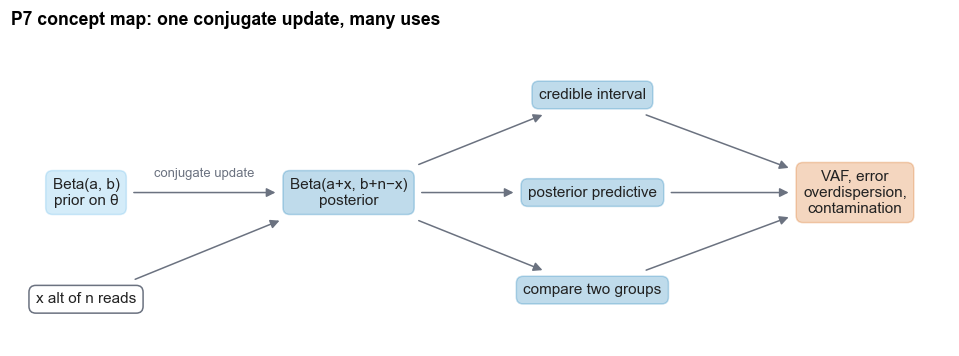

In [3]:
concept_map(
    {"beta": (0.08, 0.5, "Beta(a, b)\nprior on θ", COL["prior"]),
     "data": (0.08, 0.15, "x alt of n reads", "white"),
     "post": (0.36, 0.5, "Beta(a+x, b+n−x)\nposterior", COL["posterior"]),
     "ci": (0.62, 0.82, "credible interval", COL["posterior"]),
     "pred": (0.62, 0.5, "posterior predictive", COL["posterior"]),
     "cmp": (0.62, 0.18, "compare two groups", COL["posterior"]),
     "seq": (0.9, 0.5, "VAF, error\noverdispersion,\ncontamination", COL["alt"])},
    [("beta", "post", "conjugate update"), ("data", "post", ""), ("post", "ci", ""), ("post", "pred", ""),
     ("post", "cmp", ""), ("ci", "seq", ""), ("pred", "seq", ""), ("cmp", "seq", "")],
    title="P7 concept map: one conjugate update, many uses", size=(11, 3.6))

**그림에서 볼 것**: Beta 사전(하늘색)에 read 수를 더하기만 하면 Beta 사후(파랑)가 됩니다. 사후 하나로 구간, 다음 read 예측, 두 시료 비교를 모두 합니다. 마지막 상자(빨강)가 시퀀싱 응용입니다.

## 먼저 알아 둘 것

**기호 사전**

| 기호 | 읽는 법 | 뜻 |
|---|---|---|
| $\mathrm{Beta}(a, b)$ | 베타 에이 비 | 0~1 사이 값의 분포. 평균 $a/(a+b)$ |
| $\theta \sim \mathrm{Beta}(a,b)$ | "세타는 베타를 따른다" | θ 에 대한 믿음이 이 모양이라는 뜻 |
| $B(a,b)$ | 베타 함수 | 곡선 넓이를 1 로 맞추는 상수. 모양에는 영향 없음 |
| $\int \cdots d\theta$ | 적분 | θ 의 모든 값에 대해 더하기(연속판 Σ) |
| quantile | 분위수 | 아래쪽 넓이가 그 비율이 되는 자리. 2.5% 분위수 ~ 97.5% 분위수 = 가운데 95% |

## 1. Beta 분포: 비율에 대한 믿음을 그리는 도구

**한 줄 정의**: Beta(a, b) 는 0~1 사이 값 θ 에 대한 분포이고, 모양은 두 숫자 a, b 가 정합니다. 평균은 $a/(a+b)$ 입니다.

**왜 필요한가**: VAF, purity, 오류율, CCF 는 모두 0~1 사이 비율입니다. 이런 값에 대한 "믿음"을 그릴 그릇이 필요하고, 이항 데이터와 짝이 잘 맞는(아래 2 절) 그릇이 Beta 입니다.

**숫자로 따라가기**

| 분포 | 평균 | a + b | 모양 |
|---|---|---|---|
| Beta(1, 1) | 0.50 | 2 | 평평함(아무 정보 없음) |
| Beta(5, 15) | 0.25 | 20 | 0.25 근처, 꽤 퍼짐 |
| Beta(50, 150) | 0.25 | 200 | 0.25 근처, 좁음 |

a + b 는 사후 평균 식에서 사전이 갖는 무게입니다. Beta(1, 1) 은 a + b = 2 인데 왜 "정보 없음"인지는 3 절에서 봅니다(가상의 read 를 세는 방법이 두 가지입니다).

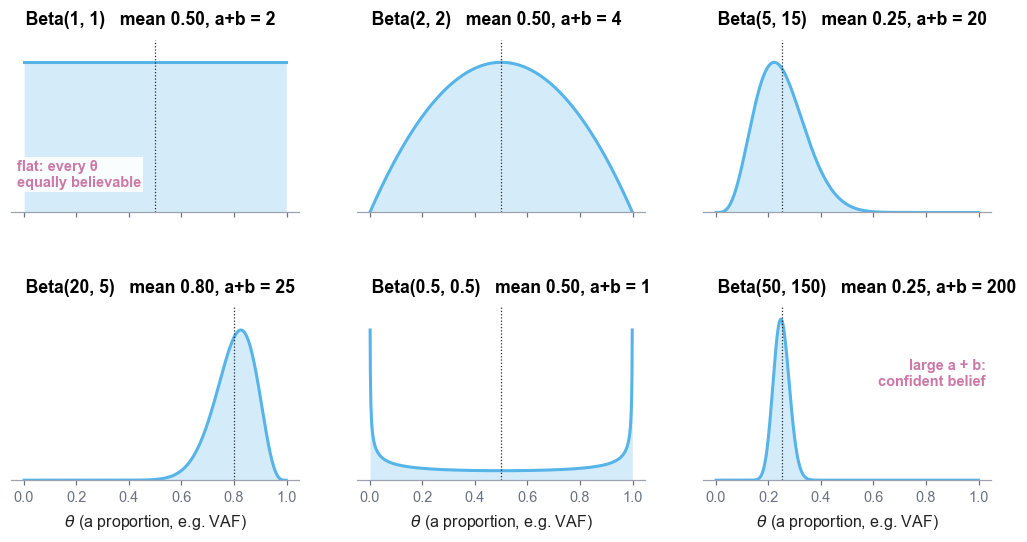

In [4]:
draw_beta_shapes()

**그림에서 볼 것**
- 점선이 평균 $a/(a+b)$ 입니다. Beta(5, 15) 와 Beta(50, 150) 은 평균이 0.25 로 같지만, a + b 가 큰 쪽이 훨씬 좁습니다.
- Beta(1, 1) 은 평평하고, Beta(0.5, 0.5) 는 0 과 1 양 끝으로 몰립니다("아주 작거나 아주 크다"는 믿음).
- a + b 는 "믿음의 세기"입니다. 3 절에서 이것이 가상의 read 수처럼 작동하는 것을 봅니다.

**수식 풀어 읽기**

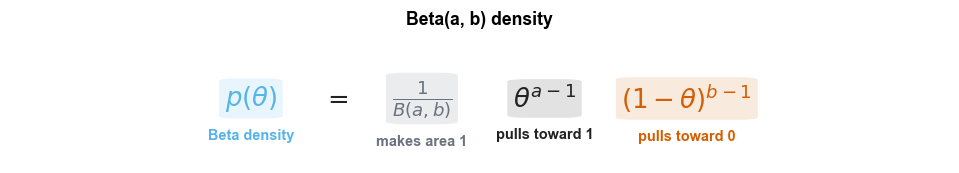

In [5]:
show_formula([
    (r"$p(\theta)$", COL["prior"], "Beta density"),
    (r"$=$", None, None),
    (r"$\frac{1}{B(a,b)}$", COL["muted"], "makes area 1"),
    (r"$\theta^{a-1}$", COL["ink"], "pulls toward 1"),
    (r"$(1-\theta)^{b-1}$", COL["alt"], "pulls toward 0"),
], title="Beta(a, b) density")

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $\theta^{a-1}$ | "세타의 a−1 제곱" | a 가 클수록 오른쪽(1 쪽)으로 무게 | Beta(20, 5) 가 오른쪽에 있는 이유 |
| $(1-\theta)^{b-1}$ | "1−세타의 b−1 제곱" | b 가 클수록 왼쪽(0 쪽)으로 무게 | Beta(5, 15) 가 왼쪽에 있는 이유 |
| $1/B(a,b)$ | 정규화 상수 | 곡선 아래 넓이를 1 로 | 높이만 맞춤 |

P5 의 이항 우도 $\theta^x(1-\theta)^{n-x}$ 와 생김새가 똑같다는 점을 기억하세요. 이것이 다음 절의 열쇠입니다.

**시뮬레이션으로 확인**: Beta(5, 15) 에서 20 만 개를 뽑아 평균이 0.25, 분산이 $ab/[(a+b)^2(a+b+1)] = 75/8400 = 0.00893$ 인지 봅니다(분산 식은 scipy 의 값과 대조).

In [6]:
rng = np.random.default_rng(0)
s = rng.beta(5, 15, 200_000)
print(f"mean {s.mean():.4f} (0.25), var {s.var():.5f} ({75 / 8400:.5f}), scipy var {stats.beta.var(5, 15):.5f}")
assert abs(s.mean() - 0.25) < 0.002 and abs(s.var() - 75 / 8400) < 3e-4 and abs(stats.beta.var(5, 15) - 75 / 8400) < 1e-12

mean 0.2503 (0.25), var 0.00898 (0.00893), scipy var 0.00893


## 2. 켤레: Beta 사전 + 이항 데이터 = Beta 사후

**한 줄 정의**: 사전이 Beta(a, b) 이고 n 번 중 x 번 성공을 보면, 사후는 **Beta(a + x, b + n − x)** 입니다. 사전과 사후가 같은 꼴인 성질을 켤레(conjugacy)라 부르고, Beta 는 이항 우도의 켤레 사전입니다 [1].

**왜 필요한가**: P6 에서는 곡선을 격자 위에서 곱하고 나눴습니다. 켤레를 쓰면 그 계산이 **숫자 두 개 더하기**가 됩니다. 그리고 사전의 a, b 를 "이미 본 가상의 성공·실패 수"로 읽을 수 있습니다(BDA3 는 켤레 사전을 "additional data"처럼 해석할 수 있다고 적습니다 [1]).

**숫자로 따라가기**: 사전 Beta(2, 2), read 10 개 중 변이 7 개.

| | a | b | 평균 |
|---|---|---|---|
| 사전 | 2 | 2 | 0.50 |
| 데이터 | + 7 (변이) | + 3 (참조) | 0.70 (MLE) |
| 사후 | 9 | 5 | 9/14 = 0.643 |

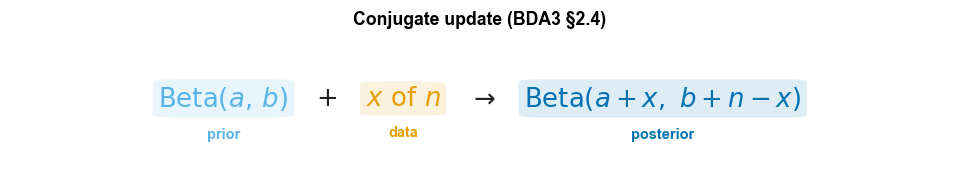

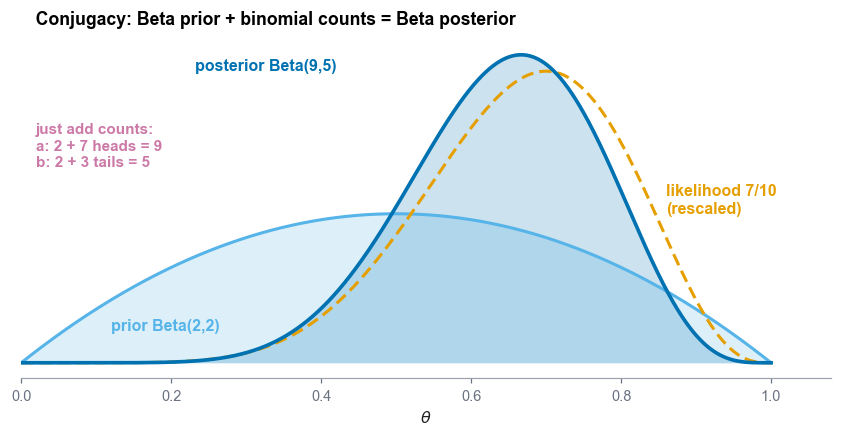

In [7]:
show_formula([
    (r"$\mathrm{Beta}(a,\,b)$", COL["prior"], "prior"),
    (r"$+$", None, None),
    (r"$x\ \mathrm{of}\ n$", COL["likelihood"], "data"),
    (r"$\rightarrow$", None, None),
    (r"$\mathrm{Beta}(a+x,\ b+n-x)$", COL["posterior"], "posterior"),
], title="Conjugate update (BDA3 §2.4)")
draw_conjugate()

**그림에서 볼 것**: 하늘색 사전(0.5 중심)과 주황 점선 우도(0.7 중심) 사이에 파란 사후가 놓입니다. 사후의 꼭대기(최빈값)는 $(a+x-1)/(a+b+n-2) = 8/12 = 0.667$, 사후 평균은 $9/14 = 0.643$ 으로 둘 다 0.7 보다 0.5 쪽입니다. 꼭대기에는 사전이 성공 1 + 실패 1 개($a-1$, $b-1$), 평균에는 $a + b = 4$ 개만큼의 무게로 들어갑니다(3 절). 왼쪽 위 글은 이 업데이트가 덧셈 두 번이라는 뜻입니다.

**수식 풀어 읽기**

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $a + x$ | 사전 a 더하기 변이 수 | 사후의 "성공" 칸 | 파란 곡선을 오른쪽으로 |
| $b + n - x$ | 사전 b 더하기 참조 수 | 사후의 "실패" 칸 | 파란 곡선을 왼쪽으로 |

왜 이렇게 되나: $\underbrace{\theta^{a-1}(1-\theta)^{b-1}}_{\text{사전}} \times \underbrace{\theta^{x}(1-\theta)^{n-x}}_{\text{우도}} = \theta^{(a+x)-1}(1-\theta)^{(b+n-x)-1}$. 지수끼리 더해질 뿐이라 같은 Beta 꼴이 됩니다.

**시뮬레이션으로 확인**: 격자에서 곱해 나눈 사후와 Beta(9, 5) 식을 비교하고, 또 "사전에서 θ 를 뽑고 → 그 θ 로 10 개를 뽑아 → 7 개가 나온 경우만 남기는" 방식(거부 표본 추출)으로 만든 θ 들의 평균이 9/14 인지 봅니다.

In [8]:
d = TH[1] - TH[0]
grid = stats.beta.pdf(TH, 2, 2) * stats.binom.pmf(7, 10, TH); grid /= grid.sum() * d
assert np.max(np.abs(grid - stats.beta.pdf(TH, 9, 5))) < 0.01
rng = np.random.default_rng(1)
th_draw = rng.beta(2, 2, 2_000_000)
kept = th_draw[rng.binomial(10, th_draw) == 7]
print(f"kept {kept.size:,} draws; mean {kept.mean():.4f} vs 9/14 = {9 / 14:.4f}")
assert abs(kept.mean() - 9 / 14) < 0.003

kept 222,906 draws; mean 0.6426 vs 9/14 = 0.6429


## 3. 사전의 세기: 가상의 read 수로 읽기

**한 줄 정의**: 사후 평균은 사전 평균과 데이터 비율의 **가중 평균**이고, 가중치는 a + b(사전)와 n(데이터)입니다.

$$\frac{a+x}{a+b+n} = \underbrace{\frac{a+b}{a+b+n}}_{\text{사전 몫}}\cdot\frac{a}{a+b} + \underbrace{\frac{n}{a+b+n}}_{\text{데이터 몫}}\cdot\frac{x}{n}$$

**왜 필요한가**: 사전을 "얼마나 세게" 둘지 감을 잡을 수 있습니다. Beta(40, 40) 사전은 사후 평균에서 read 80 개만큼의 무게를 가집니다.

**가상의 read 를 세는 두 방법**

| 무엇으로 세나 | 사전이 더하는 read | Beta(1, 1) | Beta(2, 2) | Beta(40, 40) |
|---|---|---|---|---|
| 사후 평균 식의 무게(위 식) | $a + b$ | 2 | 4 | 80 |
| 밀도 모양(BDA3 2.4 절) | 성공 $a-1$ + 실패 $b-1$ | 0 | 2 | 78 |

BDA3 는 Beta 사전과 이항 우도를 견주어 "this prior density is equivalent to α − 1 prior successes and β − 1 prior failures"라고 적습니다 [1]. Beta(1, 1) 이 "정보 없음"(가상 read 0 개)인 것은 이 둘째 방법에서 나옵니다. 사후 꼭대기 $(a+x-1)/(a+b+n-2)$ 는 둘째 방법을, 사후 평균 $(a+x)/(a+b+n)$ 은 첫째 방법을 따릅니다. 둘의 차이는 2 개뿐이라 a + b 가 크면 무시할 만합니다.

**숫자로 따라가기** (데이터는 늘 70% 변이)

| n | 사전 Beta(2,2) 의 사후 평균 | 사전 Beta(40,40) 의 사후 평균 |
|---|---|---|
| 10 | 9/14 = 0.643 | 47/90 = 0.522 |
| 100 | 72/104 = 0.692 | 110/180 = 0.611 |
| 1000 | 702/1004 = 0.699 | 740/1080 = 0.685 |

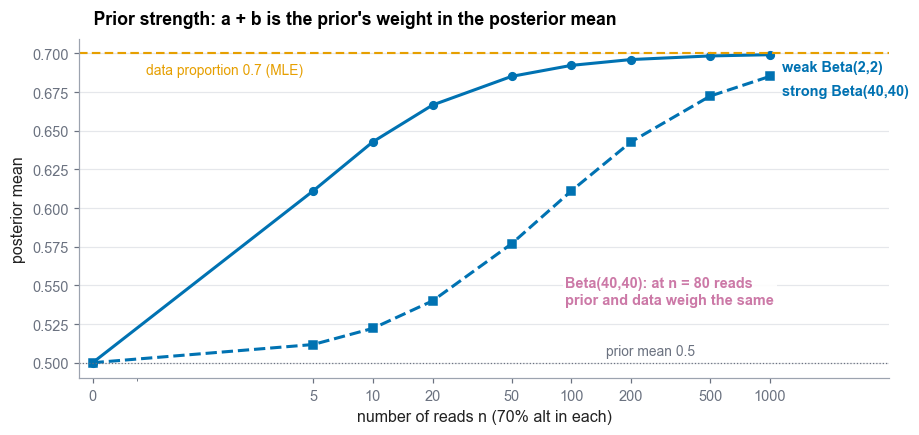

In [9]:
draw_prior_strength()
for m, want_weak, want_strong in [(10, 9 / 14, 47 / 90), (100, 72 / 104, 110 / 180), (1000, 702 / 1004, 740 / 1080)]:
    assert abs((2 + 0.7 * m) / (4 + m) - want_weak) < 1e-12 and abs((40 + 0.7 * m) / (80 + m) - want_strong) < 1e-12
assert abs((40 + 0.7 * 80) / (80 + 80) - 0.6) < 1e-12          # n = a + b = 80: 사전 0.5 와 데이터 0.7 의 한가운데

**그림에서 볼 것**: 두 선 모두 사후 평균이라 사후 색(파랑)이고, 사전만 다릅니다. 실선(약한 사전 Beta(2,2))은 read 10~20 개만 있어도 주황 점선(데이터 0.7) 가까이 갑니다. 파선(강한 사전 Beta(40,40))은 read 80 개(= a + b)에서 사후 평균이 0.6, 곧 사전 0.5 와 데이터 0.7 의 한가운데이고, 그보다 많아야 데이터 쪽이 더 무겁습니다. read 1,000 개면 둘 다 0.7 근처로 모입니다. 데이터가 충분하면 사전은 거의 상관없어진다는 뜻입니다.

## 4. 신용구간과 신뢰구간

**한 줄 정의**
- **신용구간**(credible interval, 사후 구간): 사후 분포의 가운데 95% 넓이. "데이터를 봤을 때 θ 가 이 안에 있을 확률이 95%" [1].
- **신뢰구간**(confidence interval): 같은 실험을 여러 번 반복하면 그 구간들의 95% 이상이 진짜 θ 를 포함하도록 만든 규칙. BDA3 는 "반복 표본에서 적어도 100(1−α)% 의 시간 θ₀ 를 포함하면 신뢰 범위"라고 정의하고, 확률 구간과 구별하려고 'confidence' 라는 말을 골랐다고 적습니다 [1].

**왜 필요한가**: 둘은 숫자가 비슷하게 나오는 일이 많지만 뜻이 다릅니다. BDA3 는 작은 표본에서도 베이즈 사후 구간이 반복 표본에서 명목값에 가까운 신뢰 범위를 갖는 경우가 많다고 적습니다 [1]. 아래에서 read 20 개, 진짜 VAF 0.1 인 실험(낮은 VAF 는 시퀀싱에서 흔합니다)을 반복해 직접 봅니다.

**숫자로 따라가기**: 20 개 중 6 개가 변이면
- Wald 구간 $\hat p \pm 1.96\sqrt{\hat p(1-\hat p)/n}$ = 0.30 ± 0.20 → 0.10–0.50. 정규분포 근사로 만든 **명목상(근사) 95%** 신뢰구간입니다. 근사가 맞을 때만 실제로 95% 를 덮습니다.
- 평평한 사전의 사후 Beta(7, 15) 의 가운데 95% → 아래 셀에서 계산

**Wald 가 0 근처에서 틀리는 이유**: Wald 는 $\hat p$ 를 가운데 둔 좌우 대칭인 정규분포를 가정합니다. 진짜 θ 가 0 근처면 x 는 0 아래로 갈 수 없어 분포가 오른쪽으로 치우치므로 이 근사가 맞지 않습니다. 그래서 구간이 0 아래로 내려가기도 하고(20 개 중 1 개면 0.05 ± 0.096 → −0.046–0.146, 음수 VAF), x = 0 이면 $\hat p(1-\hat p) = 0$ 이라 폭이 0 인 점이 됩니다. Beta 사후의 구간은 늘 0~1 안에 있습니다.

Wald     : [0.099 0.501]   1/20: [-0.046  0.146]  credible 1/20: [0.012 0.238]
credible : [0.146 0.522]


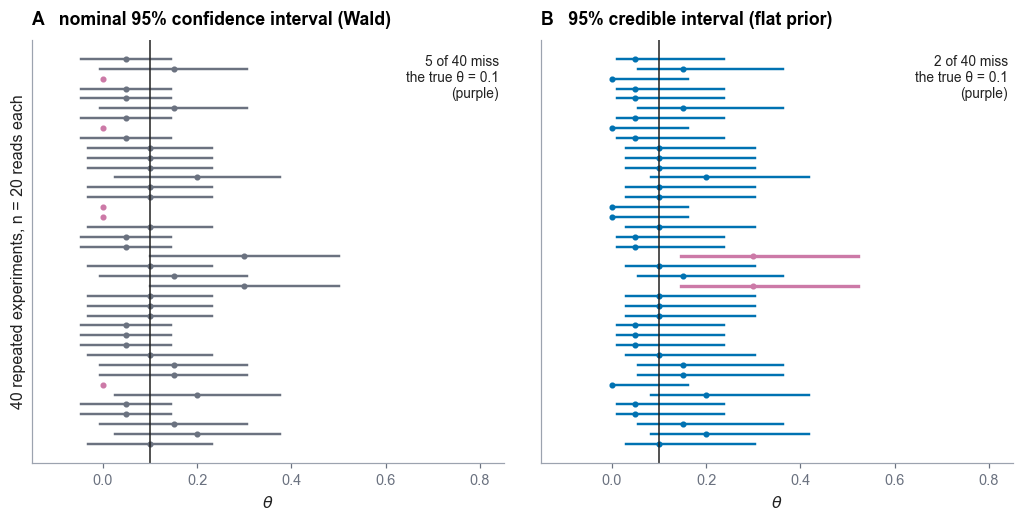

true θ = 0.1, n = 20: Wald covers 0.876, credible (flat prior) covers 0.957
true θ = 0.3, n = 20: Wald covers 0.947, credible (flat prior) covers 0.975


In [10]:
print("Wald     :", np.round(wald(6, 20), 3), "  1/20:", np.round(wald(1, 20), 3), " credible 1/20:", np.round(bayes_ci(1, 20), 3))
assert wald(1, 20)[0] < 0 and bayes_ci(1, 20)[0] > 0
print("credible :", np.round(bayes_ci(6, 20), 3))
draw_coverage(theta=0.1)

def coverage(theta, n):
    """반복 실험에서 구간이 θ 를 포함하는 비율을 정확히(가능한 x 0..n 을 모두 더해) 계산"""
    k = np.arange(n + 1); pk = stats.binom.pmf(k, n, theta)
    lw, hw = wald(k, n); lb, hb = bayes_ci(k, n)
    return np.sum(pk * ((lw <= theta) & (theta <= hw))), np.sum(pk * ((lb <= theta) & (theta <= hb)))

for th_true in (0.1, 0.3):
    cw, cb = coverage(th_true, 20)
    print(f"true θ = {th_true}, n = 20: Wald covers {cw:.3f}, credible (flat prior) covers {cb:.3f}")
cw1, cb1 = coverage(0.1, 20); cw3, cb3 = coverage(0.3, 20)
assert cw1 < 0.9 and 0.94 < cb1 < 0.98          # 낮은 VAF: Wald 가 모자람
assert abs(cw3 - 0.95) < 0.01                   # θ = 0.3: Wald 도 95% 근처
rng = np.random.default_rng(11); xs = rng.binomial(20, 0.1, 20_000)          # 시뮬레이션으로도 확인
lo_w, hi_w = wald(xs, 20); assert abs(np.mean((lo_w <= 0.1) & (0.1 <= hi_w)) - cw1) < 0.01

**그림에서 볼 것**
- 가로선 하나가 실험 하나(read 20 개)의 구간이고, 점이 그 실험의 비율 x/20 입니다. 세로선이 진짜 θ = 0.1 입니다.
- 자주색 선은 진짜 값을 놓친 구간입니다. 실험마다 구간이 달라지므로, "구간이 θ 를 포함할 확률"은 구간을 만드는 **규칙**의 성질입니다(신뢰구간의 뜻).
- A 에서 x = 0 인 실험은 Wald 구간이 폭 0 인 점이 되어 늘 놓칩니다. 낮은 VAF·작은 표본에서 Wald 구간이 약한 이유입니다.
- 위 셀의 정확한 계산(이 노트북의 결과): θ = 0.1 에서 Wald 는 약 88%, 평평한 사전의 사후 구간은 약 96% 의 실험에서 θ 를 포함합니다. θ = 0.3 에서는 Wald 도 95% 근처입니다.
- 그래도 해석은 다릅니다. 신용구간은 "이 데이터 하나"에 대해 θ 의 확률을 말하고, 신뢰구간은 "반복할 때 규칙이 얼마나 자주 맞나"를 말합니다.

## 5. 사후 예측: 다음 read 는 어떻게 나올까

**한 줄 정의**: 사후 예측 분포는 "θ 를 하나로 정하지 않고, 믿을 만한 모든 θ 에 대해 예측을 평균한 것"입니다. BDA3 식 (1.4): $p(\tilde y\mid y) = \int p(\tilde y\mid\theta)\,p(\theta\mid y)\,d\theta$ [1].

**왜 필요한가**: θ 를 MLE 하나로 고정해 예측하면(plug-in) θ 의 불확실성을 빼먹어 예측이 너무 좁아집니다. 이항 + Beta 사후의 예측은 **베타–이항 분포**가 됩니다(scipy `betabinom`).

**숫자로 따라가기**: 평평한 사전, read 20 개 중 변이 6 개 → 사후 Beta(7, 15). 다음 read 30 개에서 변이 수를 예측합니다.

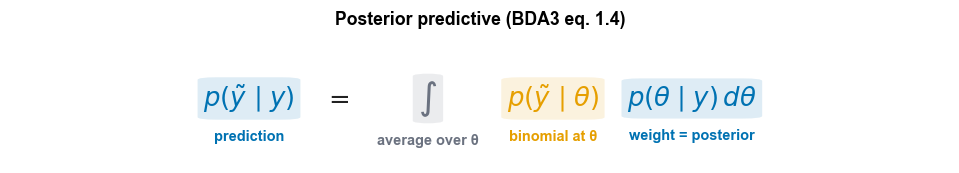

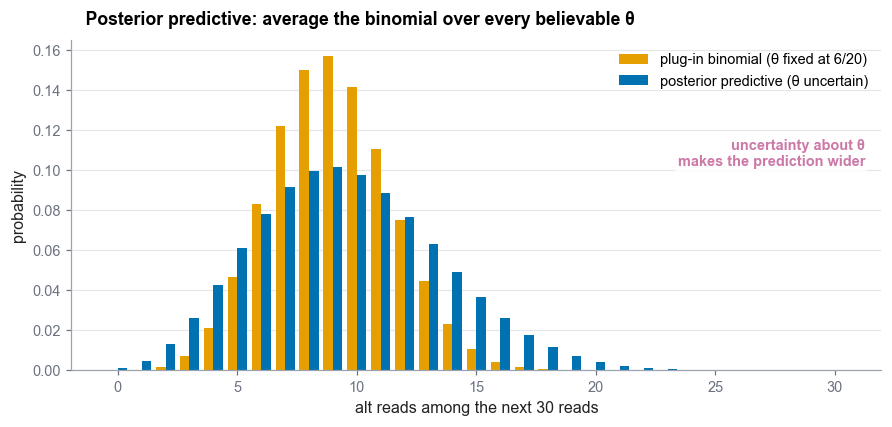

variance: plug-in 6.30, predictive 14.71


In [11]:
show_formula([
    (r"$p(\tilde y\mid y)$", COL["posterior"], "prediction"),
    (r"$=$", None, None),
    (r"$\int$", COL["muted"], "average over θ"),
    (r"$p(\tilde y\mid\theta)$", COL["likelihood"], "binomial at θ"),
    (r"$p(\theta\mid y)\,d\theta$", COL["posterior"], "weight = posterior"),
], title="Posterior predictive (BDA3 eq. 1.4)")
pp, plug = draw_predictive()
rng = np.random.default_rng(2)
th_s = rng.beta(7, 15, 400_000); y_new = rng.binomial(30, th_s)
sim_pp = np.bincount(y_new, minlength=31) / y_new.size
print(f"variance: plug-in {np.sum(np.arange(31) ** 2 * plug) - np.sum(np.arange(31) * plug) ** 2:.2f}, "
      f"predictive {np.sum(np.arange(31) ** 2 * pp) - np.sum(np.arange(31) * pp) ** 2:.2f}")
assert np.max(np.abs(sim_pp - pp)) < 0.004

**그림에서 볼 것**: 주황(θ 를 0.3 에 고정)보다 파랑(사후 예측)이 양쪽으로 더 퍼져 있습니다. read 20 개로는 θ 를 0.3 이라고 확신할 수 없으니, 다음 30 개의 변이 수도 더 넓게 열어 둬야 한다는 뜻입니다. 위 셀은 "사후에서 θ 를 뽑고 → 그 θ 로 30 개를 뽑는" 시뮬레이션이 베타–이항 식과 같음을 확인했습니다.

## 6. 두 군 비교: 사후 표본으로 차이를 직접 보기

**한 줄 정의**: 두 비율 θ_A, θ_B 의 사후에서 표본을 많이 뽑아 $\theta_A - \theta_B$ 를 계산하면, 그 값들이 **차이의 사후 분포**입니다.

**왜 필요한가**: "A 가 B 보다 클 확률", "차이가 0.1 이상일 확률"처럼 바로 알고 싶은 질문에 답합니다. 식을 따로 유도할 필요가 없습니다(이 노트북의 방법. 같이 볼 장: Think Bayes 11장 "Comparison" [3]).

**숫자로 따라가기**: 시료 A 는 40 개 중 12 개, 시료 B 는 38 개 중 5 개가 변이 read. 평평한 사전이면 사후 Beta(13, 29), Beta(6, 34).

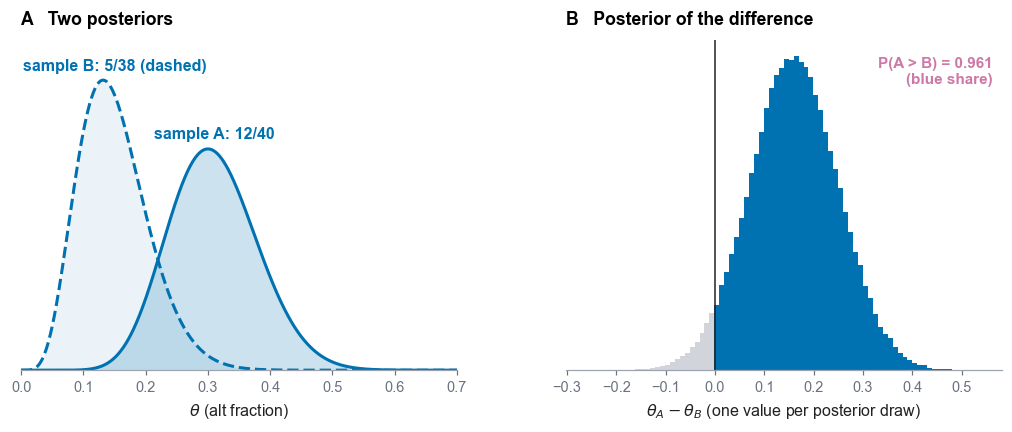

P(A > B): sampling 0.9613, numerical integration 0.9614


In [12]:
rng = np.random.default_rng(3)
draws = {"a": rng.beta(13, 29, 200_000), "b": rng.beta(6, 34, 200_000)}
draw_two_groups(draws=draws)
p_ab = np.mean(draws["a"] > draws["b"])
grid_p = np.sum(stats.beta.pdf(TH, 13, 29) * stats.beta.cdf(TH, 6, 34)) * d      # 수치 적분으로 같은 값
print(f"P(A > B): sampling {p_ab:.4f}, numerical integration {grid_p:.4f}")
assert abs(p_ab - grid_p) < 0.003

**그림에서 볼 것**: 둘 다 사후라 같은 파랑이고, A(실선)는 0.3 근처, B(파선)는 0.15 근처입니다. B 패널은 두 사후에서 하나씩 뽑아 뺀 값 20 만 개의 히스토그램이고, 0 보다 오른쪽(파랑) 몫이 P(A > B) 입니다. 같은 값을 적분으로도 계산해 맞는지 확인했습니다.

## 7. 시퀀싱 응용

### 7-1. 낮은 깊이의 VAF

**한 줄 정의**: 같은 VAF 라도 read 가 적으면 사후가 넓습니다. 사후 폭이 그 VAF 의 정직한 오차 막대입니다.

**숫자로 따라가기**: 8 개 중 2 개, 100 개 중 25 개. 둘 다 VAF 0.25.

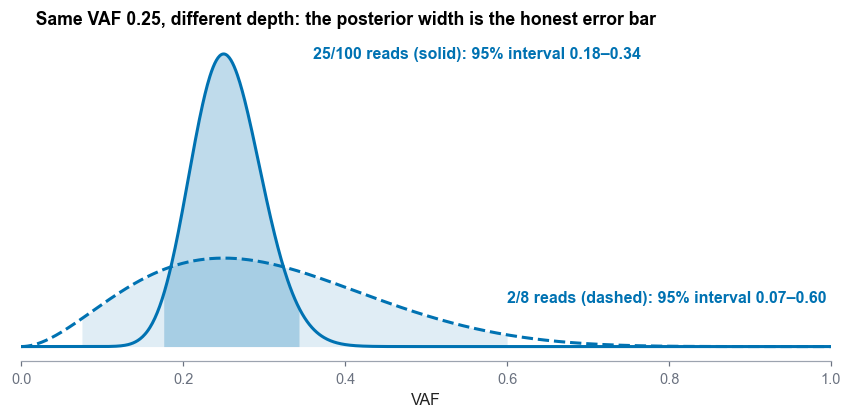

2/8: 0.07-0.60;  25/100: 0.18-0.34


In [13]:
draw_low_depth()
lo8, hi8 = bayes_ci(2, 8); lo100, hi100 = bayes_ci(25, 100)
print(f"2/8: {lo8:.2f}-{hi8:.2f};  25/100: {lo100:.2f}-{hi100:.2f}")
assert (hi8 - lo8) > 2.5 * (hi100 - lo100)

**그림에서 볼 것**: 둘 다 사후입니다. 파선(2/8)의 95% 구간은 0.07–0.60 정도로 넓어서, 이 VAF 가 클론성(예: 0.25)인지 subclone(예: 0.1)인지 가를 수 없습니다. 실선(25/100)은 0.18–0.34 정도로 좁습니다. 칠한 부분이 95% 구간입니다. 낮은 깊이에서 CCF·subclone 판정이 흔들리는 이유가 이것이고, P9 에서 purity·CN 을 넣어 같은 생각을 CCF 로 옮깁니다.

### 7-2. 과분산: 정상 시료들의 오류는 이항보다 더 퍼진다

**한 줄 정의**: 같은 자리의 시퀀싱 오류율이 시료마다 조금씩 다르면, 오류 read 수는 이항 하나보다 넓게 퍼집니다. 오류율 자체를 Beta 로 두면 오류 read 수는 **베타–이항**이 됩니다.

**실제 도구**: EBCall 은 짝이 아닌 정상 시료 여러 개로 자리마다 시퀀싱 오류가 Beta-binomial 분포를 따른다고 모형화하고, 그 모수를 추정한 뒤 종양의 allele 빈도를 이 오류 분포와 비교해 오류를 걸러냅니다 [5].

**숫자로 따라가기**: 정상 시료 200 개, 깊이 60, 이 자리 오류율 평균 0.5% 이지만 시료마다 다름(이 노트북의 장난감). 종양에서는 60 개 중 4 개가 변이로 보입니다.

pooled error rate 0.0043;  beta-binomial fit a = 0.25, b = 57.6
variance of counts: observed 0.532, binomial 0.259
inflation: fitted 1 + (n-1)ρ = 2.00;  observed / binomial = 2.06


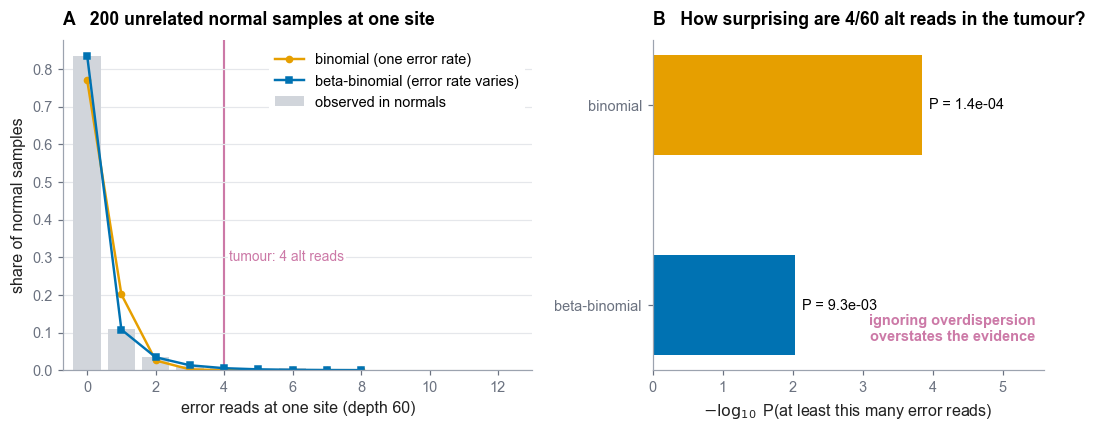

In [14]:
rng = np.random.default_rng(8)
depth, n_norm = 60, 200
err_rate = rng.beta(0.3, 60, n_norm)                         # 시료마다 다른 오류율(평균 약 0.5%)
counts = rng.binomial(depth, err_rate)
binom_p = counts.sum() / (depth * n_norm)                     # 이항 하나로 볼 때의 오류율(MLE)

def bb_negll(params):
    a, b = np.exp(params)
    return -np.sum(stats.betabinom.logpmf(counts, depth, a, b))

from scipy.optimize import minimize
fit = np.exp(minimize(bb_negll, x0=np.log([1.0, 150.0]), method="Nelder-Mead").x)
print(f"pooled error rate {binom_p:.4f};  beta-binomial fit a = {fit[0]:.2f}, b = {fit[1]:.1f}")
print(f"variance of counts: observed {counts.var():.3f}, binomial {depth * binom_p * (1 - binom_p):.3f}")
rho_bb = 1 / (fit.sum() + 1)                                  # 베타–이항: Var = n θ(1-θ) [1 + (n-1) ρ]
th_bb = fit[0] / fit.sum()
var_bb = depth * th_bb * (1 - th_bb) * (1 + (depth - 1) * rho_bb)
print(f"inflation: fitted 1 + (n-1)ρ = {1 + (depth - 1) * rho_bb:.2f};  observed / binomial = {counts.var() / (depth * binom_p * (1 - binom_p)):.2f}")
assert abs(var_bb - stats.betabinom.var(depth, *fit)) < 1e-9
draw_overdispersion(counts, depth, fit, binom_p, tumour_alt=4)
assert counts.var() > 1.3 * depth * binom_p * (1 - binom_p)                      # 과분산이 실제로 있음
assert stats.betabinom.sf(3, depth, *fit) > 10 * stats.binom.sf(3, depth, binom_p)  # 그림 B 의 메시지

**그림에서 볼 것**
- A: 회색 막대는 정상 시료 200 개에서 실제로 센 오류 read 수입니다. 관측은 이항(주황) 예상보다 0 개인 시료도 많고 2 개 이상인 시료도 많아서, 양쪽으로 더 퍼져 있습니다(과분산). 파랑(베타–이항)은 이 모양을 따라갑니다. 자주색 선이 종양에서 본 4 개입니다.
- B: 종양의 "4 개 이상"이 오류만으로 나올 확률입니다. 이항으로 보면 훨씬 작게(더 놀랍게) 나오고, 베타–이항으로 보면 덜 놀랍습니다. 과분산을 무시하면 증거를 부풀리게 됩니다.

**얼마나 더 퍼지나**: 베타–이항의 분산은 $n\bar\theta(1-\bar\theta)\,[1 + (n-1)\rho]$, $\rho = 1/(a+b+1)$ 입니다($\bar\theta = a/(a+b)$). 대괄호가 "이항보다 몇 배"이고, 위에서 맞춘 a, b 로는 약 2.0 배, 관측한 분산은 이항의 약 2.06 배입니다(위 출력). 식은 scipy `betabinom.var` 와 같은지 셀에서 대조했습니다.

> **실제 도구와 다른 점**: EBCall 은 + 가닥과 − 가닥의 read 를 따로 세고, 가닥마다 α, β 를 짝이 아닌 정상 시료들로 최대우도 추정하며, 과적합을 막으려고 모수 범위를 제한합니다. 그리고 두 가닥의 P 값을 Fisher 방법(자유도 4 인 카이제곱)으로 합칩니다 [5]. 여기서는 가닥을 나누지 않았고 모수 범위도 제한하지 않았습니다.

### 7-3. 정상 시료에 섞인 종양 DNA

**한 줄 정의**: 정상 시료(혈액 등)에 종양 DNA 가 비율 c 만큼 섞이면, 종양의 체세포 변이가 정상 시료에도 아주 낮은 VAF 로 보입니다.

**장난감 모형(이 노트북)**: 정상 시료의 변이 read 비율이 "c × (그 변이의 종양 VAF)"라고 놓고, 체세포 변이 500 곳의 정상 read 를 모두 모아 c 의 사후를 격자로 구합니다. 자리 하나에는 변이 read 가 0~2 개뿐이지만, 많이 모으면 c 를 좁게 잡을 수 있습니다.

**실제 도구**: 최신 PURPLE 설명서(master, 이 노트북을 쓸 때 커밋 3807790)는 SAGE 가 찾은 tumour-in-normal 수준(TINC)을 써서, germline 으로 불린 SV 중 체세포로 옮길 것을 다시 본다고 적습니다(`recoveryTINC = tumorAF × (2 × sageTINC + 0.02)`) [6]. 이 기능은 PURPLE 4.1 설명서에는 없는 최신판 내용이고, SAGE 가 TINC 를 어떻게 추정하는지는 이 노트북에서 확인하지 않았습니다. PURPLE 4.1 설명서의 AMBER 는 이와 다른 **종양 시료의 오염 검사**를 합니다. 정상 시료에서 동형접합인 자리에 종양에서 변이 read 가 보이는지 세고, 그 수를 포아송 모형으로 보아 오염 비율을 추정합니다 [7].

alt reads per site in the normal: max 2, sites with 0 alt: 75%


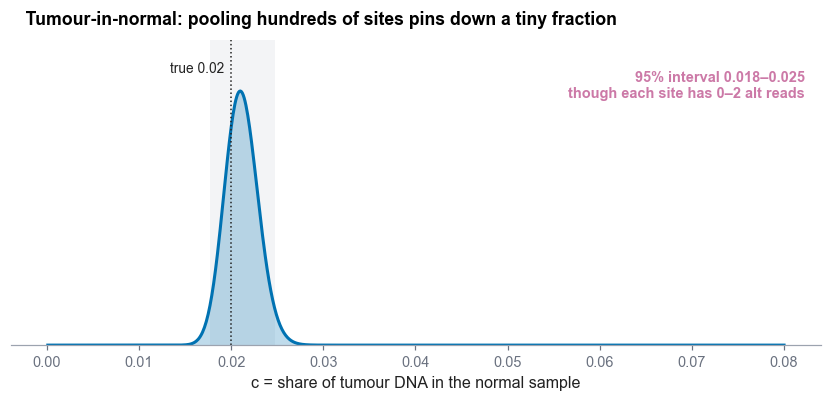

In [15]:
rng = np.random.default_rng(8)
n_sites, c_true = 500, 0.02
vaf_t = rng.uniform(0.15, 0.5, n_sites)                       # 종양에서의 VAF
dp_n = rng.poisson(40, n_sites)                                # 정상 시료 깊이
alt_n = rng.binomial(dp_n, c_true * vaf_t)
cg = np.linspace(1e-4, 0.08, 800)
loglik = np.array([np.sum(stats.binom.logpmf(alt_n, dp_n, c * vaf_t)) for c in cg])
post_c = np.exp(loglik - loglik.max()); post_c /= post_c.sum()     # 평평한 사전
print(f"alt reads per site in the normal: max {alt_n.max()}, sites with 0 alt: {np.mean(alt_n == 0):.0%}")
lo_c, hi_c = draw_tin(cg, post_c, c_true)
assert lo_c < c_true < hi_c and hi_c - lo_c < 0.02

**그림에서 볼 것**: 정상 시료의 자리마다 변이 read 는 대부분 0 개입니다(위 출력). 그래도 500 곳을 함께 보면 c 의 사후(파랑)가 진짜 값 0.02(점선) 근처에 좁게 모입니다. 옅은 회색 띠가 95% 구간입니다.

> **시퀀싱 데이터에서는**: Beta 와 베타–이항은 "비율"과 "비율이 시료마다 흔들리는 개수"의 기본 그릇입니다. VAF 의 불확실성(7-1), 패널 오브 노멀의 오류 모형(7-2), 섞임 비율(7-3) 모두 같은 그릇을 씁니다. Mutect2 기술 문서도 allele 비율 군집 모형에 beta 분포와 beta-binomial 을 쓴다고 적습니다 [8].

## 연습 문제

1. 사전 Beta(1, 1), read 50 개 중 변이 20 개. 사후와 사후 평균은?
2. 사전 Beta(3, 27) 은 몇 개의 "가상 read"입니까(3 절의 두 방법으로)? 평균은 얼마이고, 이 사전에 10 개 중 5 개가 오면 사후 평균은?
3. 7-1 에서 2/8 의 95% 구간이 0.25 와 0.1 을 모두 포함하는지 확인해 보세요.
4. 7-2 에서 종양 변이 read 가 8 개라면 두 모형의 P 값은 어떻게 달라질까요?

<details><summary>정답 보기</summary>

1. Beta(21, 31), 평균 $21/52 \approx 0.404$.
2. 사후 평균 식의 무게로는 a + b = 30 개, 밀도 모양(BDA3)으로는 성공 2 + 실패 26 = 28 개. 평균 0.1. 사후 Beta(8, 32), 평균 $8/40 = 0.2$.
3. 2/8 의 구간은 약 0.07–0.60 이라 둘 다 포함합니다. 이 깊이로는 클론성과 subclone 을 가를 수 없습니다.
4. 둘 다 작아지지만, 이항 쪽이 훨씬 더 빨리 작아집니다(아래 셀). 이항이면 8 개는 거의 불가능하지만, 베타–이항이면 드물지만 있을 수 있는 일입니다.

</details>

In [16]:
print("1:", 21 / 52, " 2:", 8 / 40, " 3:", np.round(bayes_ci(2, 8), 3))
print(f"4: binomial {stats.binom.sf(7, depth, binom_p):.1e}, beta-binomial {stats.betabinom.sf(7, depth, *fit):.1e}")
assert abs(21 / 52 - 0.404) < 0.001 and bayes_ci(2, 8)[0] < 0.1 and bayes_ci(2, 8)[1] > 0.25
assert stats.betabinom.sf(7, depth, *fit) > 100 * stats.binom.sf(7, depth, binom_p)

1: 0.40384615384615385  2: 0.2  3: [0.075 0.6  ]
4: binomial 2.6e-10, beta-binomial 3.3e-04


## 정리

- Beta(a, b) 는 비율에 대한 믿음입니다. 평균 $a/(a+b)$, 세기 $a+b$.
- Beta 사전 + 이항 데이터 → Beta(a + x, b + n − x). 지수끼리 더해지는 켤레 성질입니다.
- 사후 평균은 사전 평균과 데이터 비율의 가중 평균이고, 사전은 그 식에서 a + b 개 read 의 무게를 갖습니다(밀도 모양으로 세면 a − 1 + b − 1 개, Beta(1, 1) 은 0 개).
- 신용구간은 "이 데이터에서 θ 가 들어 있을 확률", 신뢰구간은 "반복할 때 규칙이 맞는 비율"입니다. Wald 구간은 근사라 낮은 VAF 에서 명목값 95% 를 못 지킵니다.
- 사후 예측은 θ 의 불확실성까지 넣어 plug-in 보다 넓습니다(베타–이항).
- 두 군 비교는 사후 표본의 차이로 바로 합니다.
- 시퀀싱에서는 낮은 깊이 VAF 의 오차, 정상 시료 오류의 과분산, 섞임 비율 추정에 같은 그릇을 씁니다.

다음 노트북(P8)은 켤레가 없는 모형(모수가 여러 개)에서 사후를 계산하는 방법, 격자 근사와 MCMC 를 다룹니다.

## 출처

| 번호 | 출처 | 이 노트북에서 쓴 곳 |
|---|---|---|
| [1] | Gelman A 외. *Bayesian Data Analysis*, 3rd ed. 비상업용 PDF: [책 누리집](https://sites.stat.columbia.edu/gelman/book/) | 2.4 절(p.34) Beta(α+y, β+n−y) 와 켤레성, 켤레 사전을 추가 데이터로 해석, "α − 1 prior successes and β − 1 prior failures", 2.3 절 사후 구간, 4.4 절(p.92) 신뢰 범위 정의, 4.5 절(p.95) 작은 표본에서도 베이즈 구간의 coverage 가 명목값에 가까운 경우가 많음, 식 (1.4) 사후 예측 |
| [2] | Blitzstein J. Harvard Statistics 110 [23강 "Beta distribution"](https://www.youtube.com/watch?v=UZjlBQbV1KU) ([재생목록](https://www.youtube.com/playlist?list=PL2SOU6wwxB0uwwH80KTQ6ht66KWxbzTIo)) | 같이 볼 강의 |
| [3] | Downey AB. *Think Bayes* 2nd ed. [4장](https://allendowney.github.io/ThinkBayes2/chap04.html), [18장 Conjugate Priors](https://allendowney.github.io/ThinkBayes2/chap18.html), [목차(11장 Comparison)](https://allendowney.github.io/ThinkBayes2/index.html) | 같이 볼 교재 |
| [4] | McElreath R. *Statistical Rethinking* 2023, [GitHub 강의표](https://github.com/rmcelreath/stat_rethinking_2023) 2강 | 같이 볼 강의 |
| [5] | Shiraishi Y 외. 2013. An empirical Bayesian framework for somatic mutation detection from cancer genome sequencing data. *Nucleic Acids Res* 41(7):e89. [doi:10.1093/nar/gkt126](https://doi.org/10.1093/nar/gkt126), [PMC3627598](https://pmc.ncbi.nlm.nih.gov/articles/PMC3627598/) | 7-2 비짝 정상 시료로 추정한 Beta-binomial 오류 모형, 가닥별 계산, 모수 범위 제한, Fisher 방법으로 두 가닥 P 값 합치기 |
| [6] | PURPLE README (master, 커밋 3807790a), [hmftools/purple@3807790](https://github.com/hartwigmedical/hmftools/blob/3807790a207b0e3ddb158a3414c9dc6a9ab49748/purple/README.md), "2. Tumor in Normal contamination recovery" | 7-3 SAGE TINC 와 recoveryTINC 식 |
| [7] | PURPLE README purple-v4.1, [hmftools/purple@purple-v4.1](https://github.com/hartwigmedical/hmftools/blob/purple-v4.1/purple/README.md), Amber 입력 절 | 7-3 AMBER 오염 검사(포아송 모형) |
| [8] | GATK 개발팀. Mutect2 기술 문서 [`docs/mutect/mutect.tex`](https://github.com/broadinstitute/gatk/blob/4.7.0.0/docs/mutect/mutect.tex) (4.7.0.0), Allele Fraction Clustering Model 절 | beta 분포 군집과 beta-binomial |

시뮬레이션, coverage, 베타–이항 분산 배수, 장난감 오류·섞임 모형의 숫자는 이 노트북에서 직접 계산한 결과입니다.